In [1]:
from fastai.vision.all import *
import os
from fastbook import *
from fastai.vision.widgets import *

In [2]:
path = Path('Training')
path.ls()

(#2) [Path('Training/Cyto'),Path('Training/Nuc')]

In [3]:
fns = get_image_files(path)
fns

(#7133) [Path('Training/Cyto/Plate10_A01_1_0.png'),Path('Training/Cyto/Plate10_A01_1_1.png'),Path('Training/Cyto/Plate10_A01_1_10.png'),Path('Training/Cyto/Plate10_A01_1_100.png'),Path('Training/Cyto/Plate10_A01_1_101.png'),Path('Training/Cyto/Plate10_A01_1_102.png'),Path('Training/Cyto/Plate10_A01_1_103.png'),Path('Training/Cyto/Plate10_A01_1_104.png'),Path('Training/Cyto/Plate10_A01_1_105.png'),Path('Training/Cyto/Plate10_A01_1_106.png')...]

In [4]:
cells = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=813),
    get_y=parent_label,
    item_tfms=Resize(224, ResizeMethod.Pad),
    batch_tfms=aug_transforms(mult=2))
dls = cells.dataloaders(path, num_workers=0)

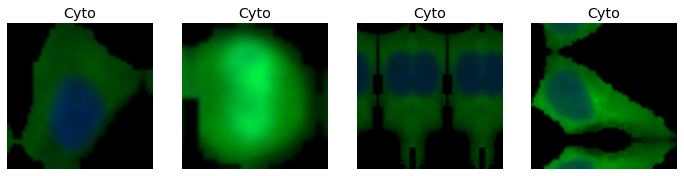

In [5]:
dls.valid.show_batch(max_n=4, nrows=1)

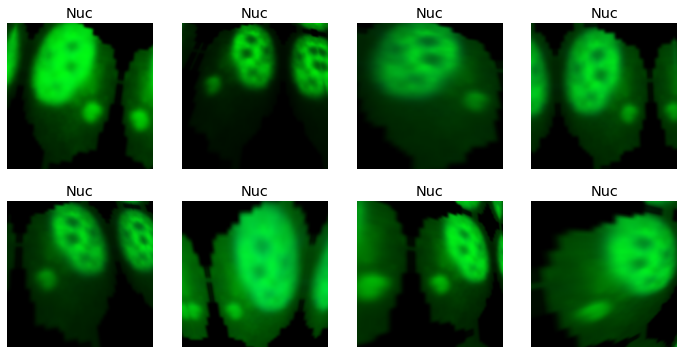

In [6]:
dls.train.show_batch(max_n=8, nrows=2, unique=True)

In [9]:
learn = cnn_learner(dls, resnet18, metrics=error_rate)

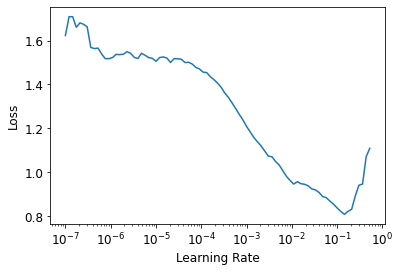

In [10]:
lr_min,lr_steep = learn.lr_find()

In [11]:
print(f"Minimum/10: {lr_min:.2e}, steepest point: {lr_steep:.2e}")

Minimum/10: 1.45e-02, steepest point: 8.32e-04


In [12]:
learn = cnn_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(30, base_lr = 3e-4)

epoch,train_loss,valid_loss,error_rate,time
0,0.598452,0.176167,0.062412,00:34


epoch,train_loss,valid_loss,error_rate,time
0,0.324119,0.158474,0.055400,00:37
1,0.281664,0.154993,0.049088,00:37
2,0.245608,0.131632,0.045582,00:38
3,0.212196,0.129356,0.042777,00:39
4,0.195262,0.133098,0.041374,00:38
5,0.176395,0.144861,0.043478,00:38
6,0.170838,0.136751,0.039271,00:37
7,0.169383,0.132764,0.040673,00:38
8,0.149686,0.122653,0.035764,00:38
9,0.150193,0.116593,0.040673,00:37


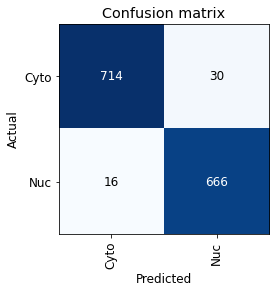

In [13]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

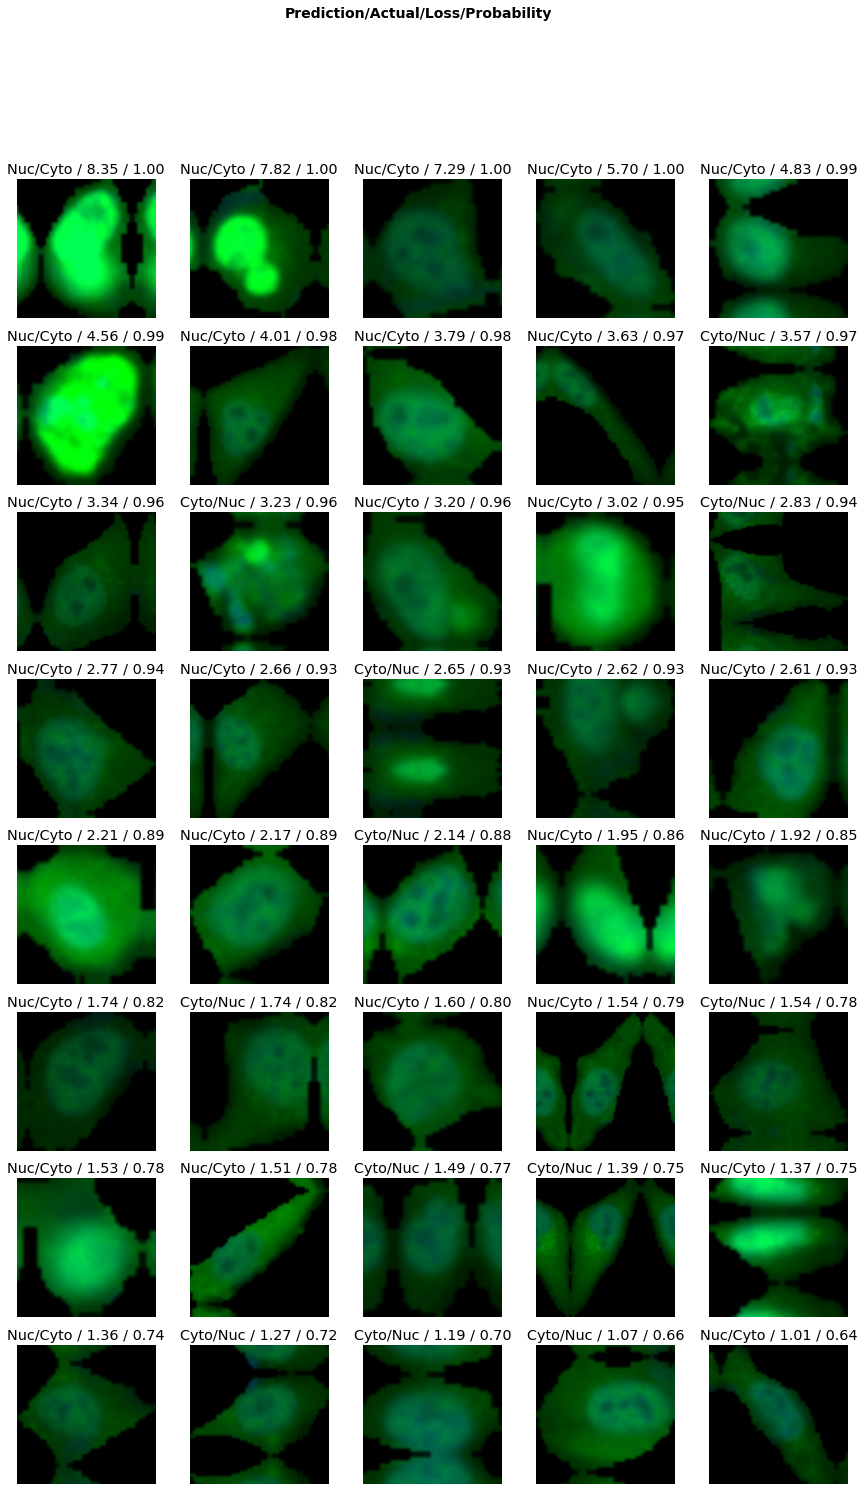

In [14]:
interp.plot_top_losses(40, nrows=8)

In [19]:
learn.export()

In [20]:
learn = load_learner('export.pkl')

In [15]:
#learn = cnn_learner(dls, resnet18, metrics=error_rate)
#learn.lr_find()

In [16]:
#learn.fit_one_cycle(3, 1e-3)

In [17]:
#learn.unfreeze()
#learn.lr_find()

In [18]:
#learn = cnn_learner(dls, resnet18, metrics=error_rate)
#learn.fit_one_cycle(3, 1e-3)
#learn.unfreeze()
#learn.fit_one_cycle(30, lr_max=slice(1e-7, 1e-6))

In [ ]:
#learn.export()